# 01 基础调制链路

自主完成星座点生成、调制映射与最小欧氏距离解调，并补全 BPSK、QPSK、8-PSK、16-QAM 四种调制方式的仿真循环。

In [1]:
# 导入依赖并准备调制、解调和 BER 统计的通用函数。
from pathlib import Path
import sys

# 从当前目录向上查找 src/sionna（若使用仓库源码则优先使用）。
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import torch
import matplotlib.pyplot as plt

# 设置 Matplotlib 中文字体，避免图标题和坐标轴中文乱码。
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "Noto Sans CJK SC",
    "Arial Unicode MS",
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False

# Word 报告中的图宽约 14.4 cm，而画布按英寸设置，插入时会被缩放，
# 因此把 matplotlib 的字号整体放大，使打印后的字号与正文（10.5 pt）接近。
plt.rcParams.update(
    {
        "font.size": 13,
        "axes.labelsize": 13,
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)

# 信道部分使用 Sionna 模块，星座映射与解映射由本实验自主实现（类似 16QAM 示例）。
from sionna.phy.channel import AWGN, RayleighBlockFading

# 固定使用 CPU，保证没有 GPU 的学生电脑也能运行。
DEVICE = "cpu"
PRECISION = "single"

# 固定随机种子，便于复现实验结果。
# 注意：Sionna 的 AWGN / 衰落信道使用自己的 torch.Generator（config.torch_rng），
# 因此除了 torch / numpy 之外还必须设置 sionna.phy.config.seed，否则噪声每次运行都不同。
from sionna.phy import config as sionna_config


def set_seed(seed=7):
    """固定 Python / NumPy / PyTorch / Sionna 四个随机源，使仿真结果可复现。"""
    torch.manual_seed(seed)
    np.random.seed(seed)
    sionna_config.seed = int(seed)


set_seed(7)

# 图、数据输出目录：便于把过程性与结果性材料归档到同一文件夹。
FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)


# 将 Eb/N0 转成 AWGN 模块需要的噪声功率谱密度 no。
def ebno_db_to_no(ebno_db, nbits, coderate=1.0):
    ebno = 10 ** (torch.as_tensor(ebno_db, dtype=torch.float32, device=DEVICE) / 10.0)
    return 1.0 / (ebno * nbits * coderate)


# 统计误比特数，BER 会在此基础上除以总 bit 数。
def count_bit_errors(b, b_hat):
    # 统一转成 int32 后逐元素比较，统计不同 bit 的个数。
    return int(torch.sum(b.to(torch.int32) != b_hat.to(torch.int32)).item())


def ber(b, b_hat):
    return count_bit_errors(b, b_hat) / b.numel()


# 生成各调制方式的星座表，BPSK/QPSK/16-QAM 归一化至平均符号能量 Es = 1。
def get_constellation(name):
    if name == "BPSK":
        # 1 bit: 0 -> -1, 1 -> +1
        pts = torch.tensor([-1.0 + 0j, 1.0 + 0j], dtype=torch.complex64, device=DEVICE)
    elif name == "QPSK":
        # 2 bit: 00, 01, 10, 11
        pts = torch.tensor(
            [1.0 + 1.0j, -1.0 + 1.0j, 1.0 - 1.0j, -1.0 - 1.0j],
            dtype=torch.complex64,
            device=DEVICE,
        ) / np.sqrt(2.0)
    elif name == "8-PSK":
        # 3 bit Gray 码映射: 相邻星座点仅相差 1 bit
        gray_order = [0, 1, 3, 2, 6, 7, 5, 4]
        angles = torch.zeros(8, dtype=torch.float32, device=DEVICE)
        for k, bit_val in enumerate(gray_order):
            angles[bit_val] = k * (2 * np.pi / 8)
        pts = torch.exp(1j * angles).to(torch.complex64)
    elif name == "16-QAM":
        # 4 bit 16-QAM 星座点（参考 16QAM/QAM_awgn.m）
        c16 = [
            1 + 1j,
            1 + 3j,
            3 + 1j,
            3 + 3j,
            -1 + 1j,
            -1 + 3j,
            -3 + 1j,
            -3 + 3j,
            -3 - 3j,
            -3 - 1j,
            -1 - 3j,
            -1 - 1j,
            1 - 1j,
            1 - 3j,
            3 - 1j,
            3 - 3j,
        ]
        pts = torch.tensor(c16, dtype=torch.complex64, device=DEVICE)
        es = torch.mean(torch.abs(pts) ** 2)
        pts = pts / torch.sqrt(es)
    else:
        raise ValueError(f"未知调制方式: {name}")
    return pts


# 类似 16QAM/modulation.m：将比特流按 nbits 查表映射到星座点
def modulate(bits, constell, nbits):
    # 把每个符号的 nbits 个比特视为一个 nbits 位二进制数（高位在前）作为星座索引。
    bits = bits.to(torch.int64)
    idx = torch.zeros(bits.shape[:-1], dtype=torch.long, device=DEVICE)
    for i in range(nbits):
        idx = (idx << 1) | bits[..., i]
    return constell[idx]


# 类似 16QAM/demodulation.m：基于最小欧氏距离判决解映射还原比特
def demodulate(rx_symbols, constell, nbits):
    # (..., 1) 与 (M,) 广播，得到接收符号到每个星座点的距离平方 (..., M)。
    dist = torch.abs(rx_symbols.unsqueeze(-1) - constell) ** 2
    idx = torch.argmin(dist, dim=-1)
    bits = torch.zeros(*idx.shape, nbits, dtype=torch.int32, device=DEVICE)
    for i in range(nbits):
        shift = nbits - 1 - i
        bits[..., i] = ((idx >> shift) & 1).to(torch.int32)
    return bits


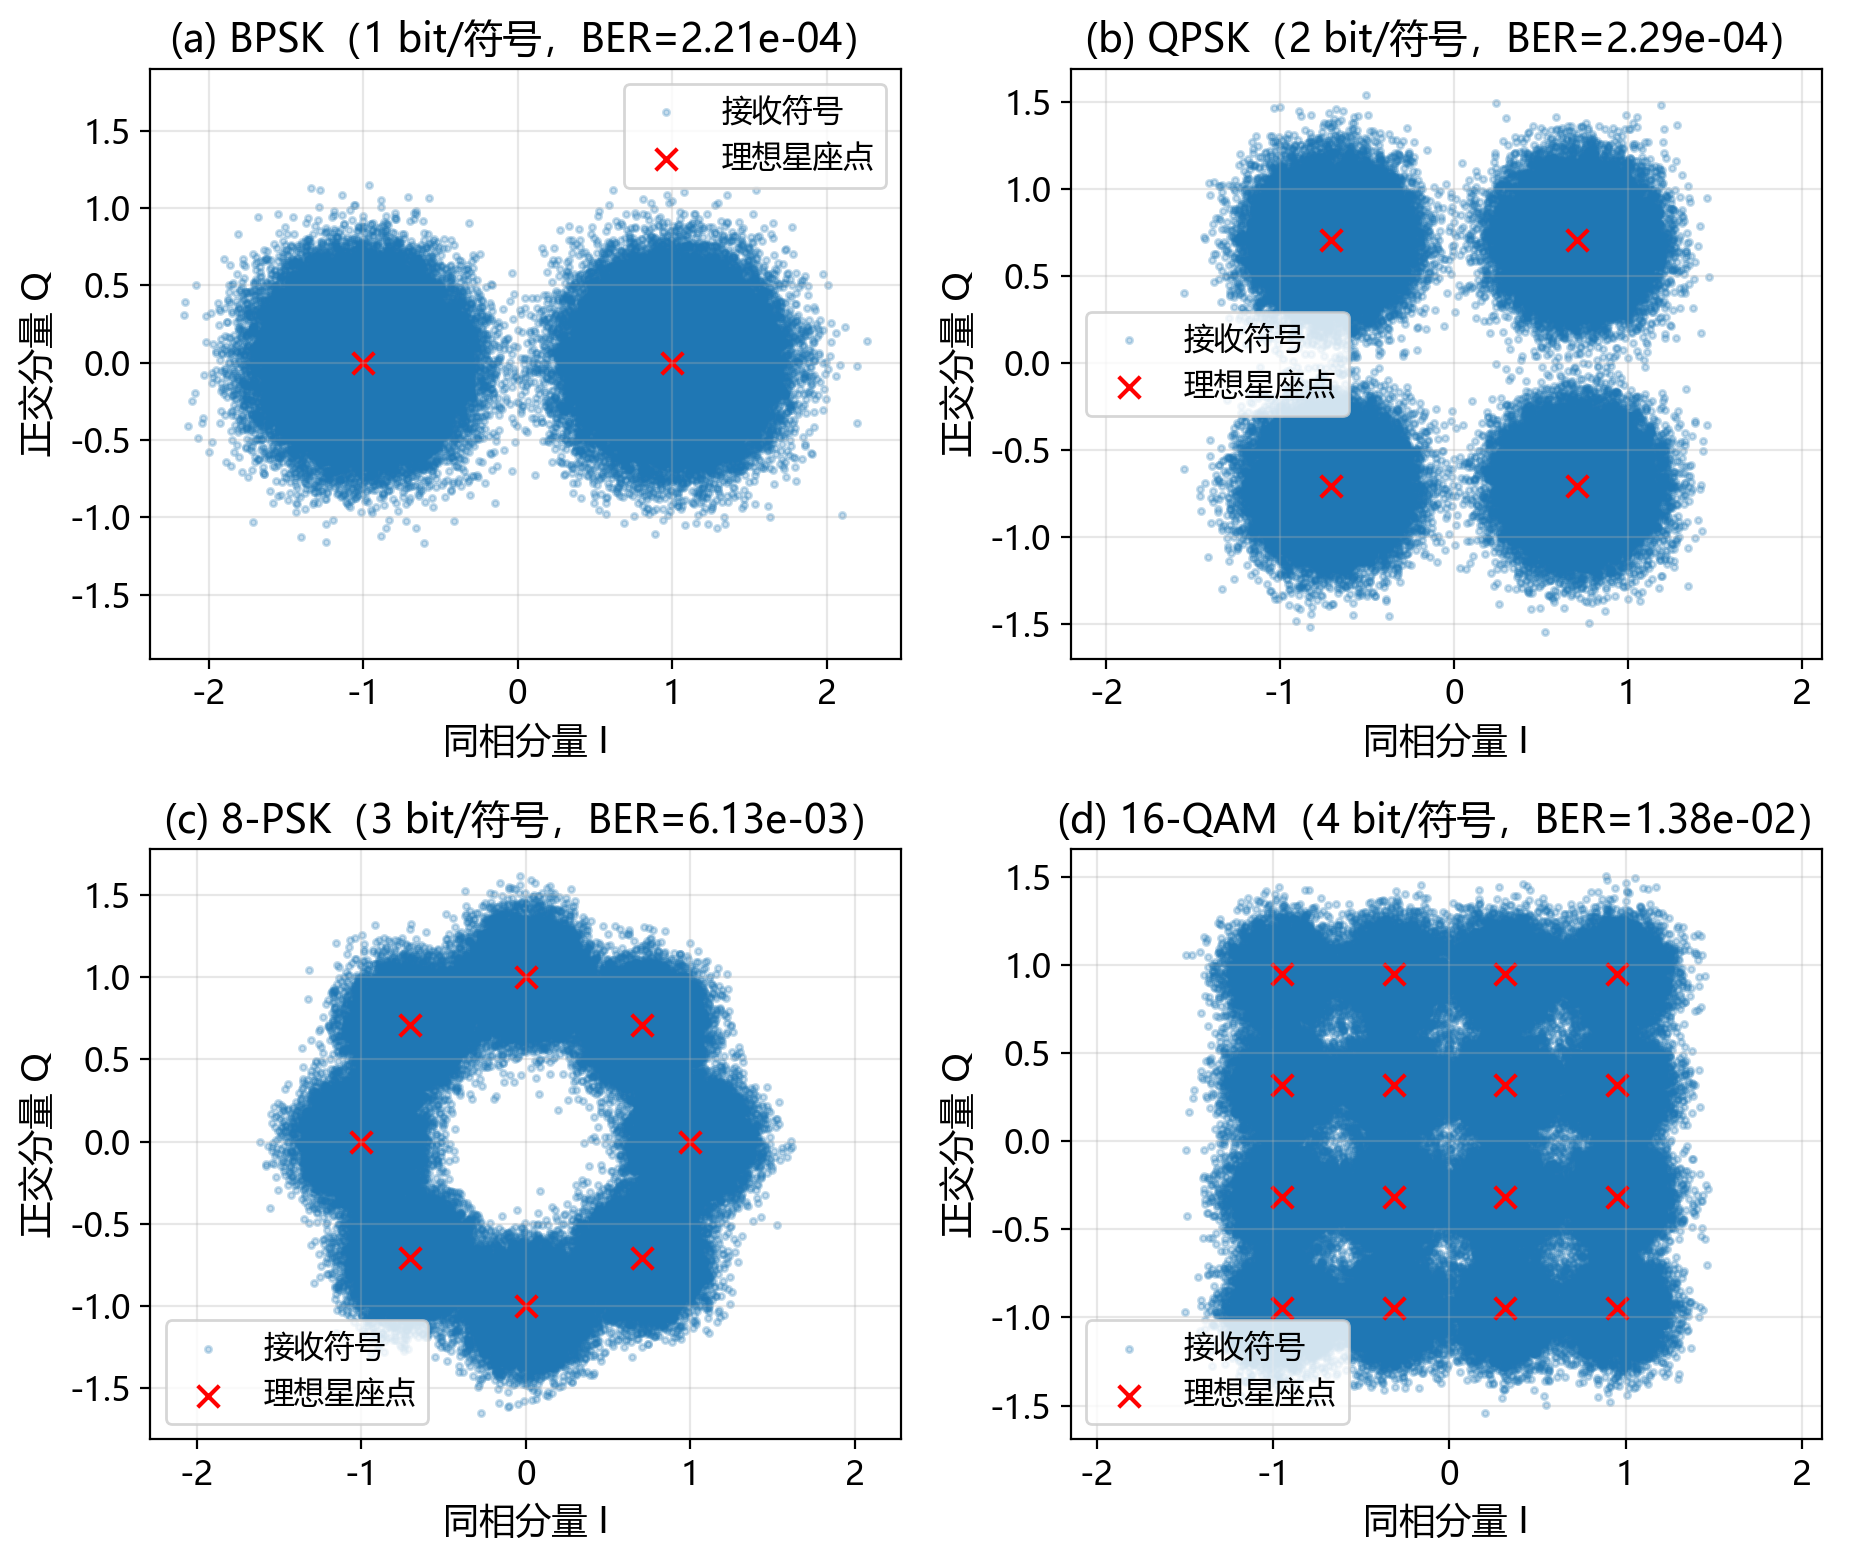

表 1  四种调制方式在 Eb/N0 = 8 dB 下的误比特率
modulation  nbits  ebno_db      ber
      BPSK      1      8.0 0.000221
      QPSK      2      8.0 0.000229
     8-PSK      3      8.0 0.006134
    16-QAM      4      8.0 0.013849


In [2]:
# 对四种调制方式：生成比特 -> 映射 -> AWGN 加噪 -> 判决解映射 -> 统计 BER，并绘制接收星座图。
MODES = {"BPSK": 1, "QPSK": 2, "8-PSK": 3, "16-QAM": 4}
EbN0_DB = 8.0
BATCH_SIZE = 512
NUM_SYMBOLS = 256

results = []

fig, axes = plt.subplots(2, 2, figsize=(9.4, 8.0))
axes = axes.ravel()

for idx, (ax, (name, nbits)) in enumerate(zip(axes, MODES.items())):
    constell = get_constellation(name)
    b = torch.randint(
        0, 2, (BATCH_SIZE, NUM_SYMBOLS, nbits), dtype=torch.int32, device=DEVICE
    )

    # 1) 发送端：比特查表映射为星座符号
    x = modulate(b, constell, nbits)
    # 2) 信道：按 Eb/N0 计算噪声功率谱密度并叠加 AWGN
    no = ebno_db_to_no(EbN0_DB, nbits)
    y = AWGN(precision=PRECISION, device=DEVICE)(x, no)
    # 3) 接收端：最小欧氏距离判决解映射
    b_hat = demodulate(y, constell, nbits)
    # 4) 统计误比特率
    this_ber = ber(b, b_hat)

    results.append(
        {"modulation": name, "nbits": nbits, "ebno_db": EbN0_DB, "ber": this_ber}
    )

    # 接收散点图：发散程度反映噪声大小，理想星座点用红色叉号标注
    ax.scatter(
        y.real.cpu().flatten(),
        y.imag.cpu().flatten(),
        s=5,
        alpha=0.25,
        c="#1f77b4",
        label="接收符号",
    )
    ax.scatter(
        constell.real.cpu(),
        constell.imag.cpu(),
        s=60,
        marker="x",
        c="red",
        linewidths=1.5,
        label="理想星座点",
    )
    ax.set_title(f"({'abcd'[idx]}) {name}（{nbits} bit/符号，BER={this_ber:.2e}）", fontsize=14)
    ax.set_xlabel("同相分量 I", fontsize=13)
    ax.set_ylabel("正交分量 Q", fontsize=13)
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.3)
    ax.axis("equal")
    ax.legend(fontsize=11, loc="best")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_received_constellation.png", dpi=200, bbox_inches="tight")
plt.show()

import pandas as pd

df_results = pd.DataFrame(results)
print("表 1  四种调制方式在 Eb/N0 = 8 dB 下的误比特率")
print(df_results.to_string(index=False))
df_results.to_csv(DATA_DIR / "01_ber_at_8dB.csv", index=False, encoding="utf-8-sig")

assert len(results) == 4


## 补充：BER 随 Eb/N0 变化曲线

在完成模板要求的 8 dB 单点统计之后，进一步扫描 Eb/N0 = 0~12 dB，
得到四种调制方式的 BER 曲线，作为报告第 3.1 节定量分析的依据。


图4  四种调制方式的 BER-Eb/N0 曲线：仿真与理论对比（AWGN 信道）


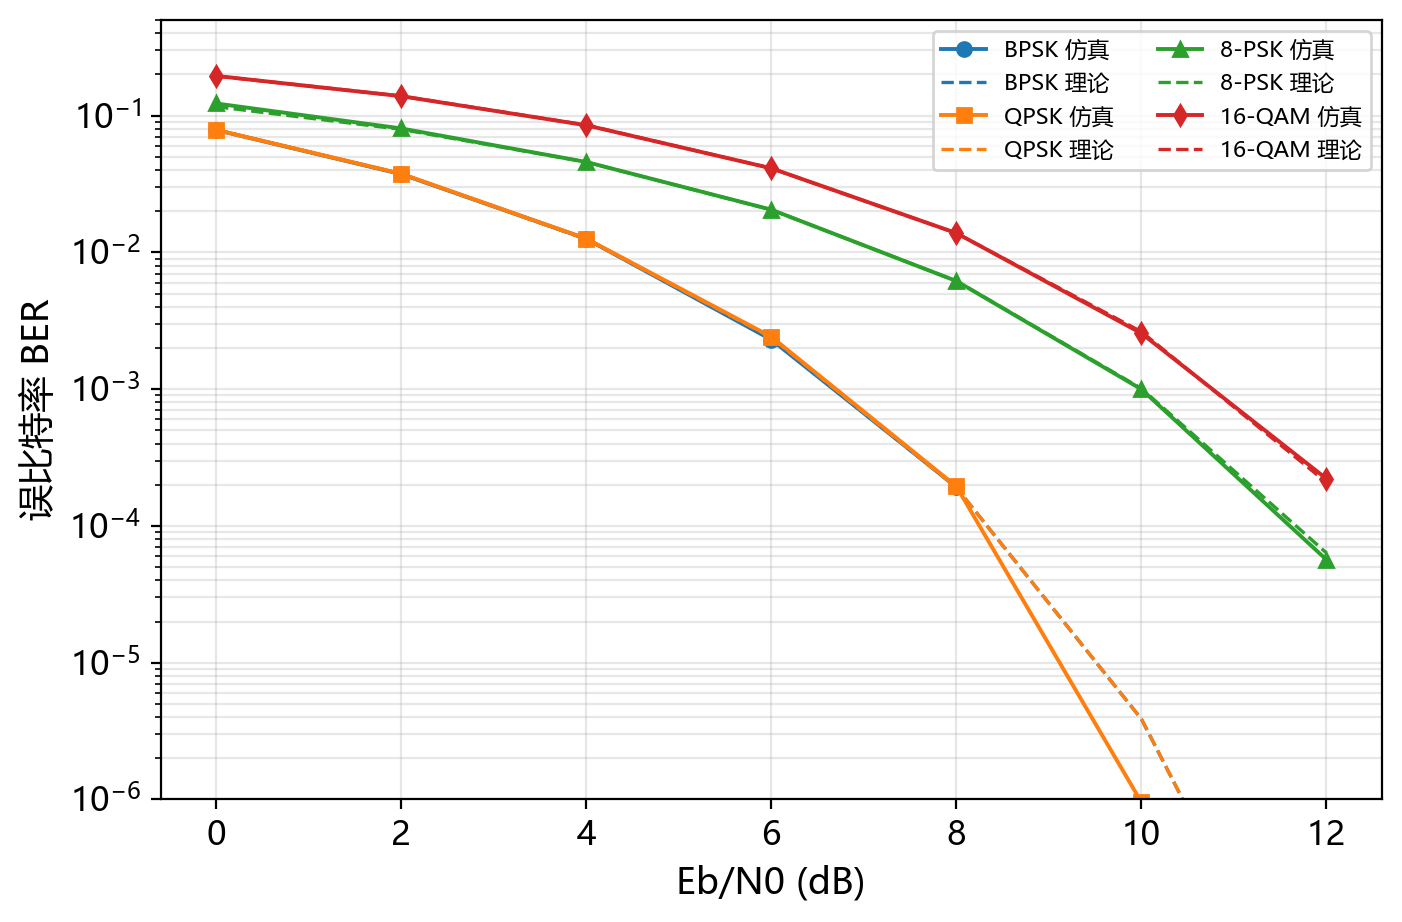

表 2  四种调制方式在不同 Eb/N0 下的仿真 BER
 EbN0_dB     BPSK         QPSK    8-PSK   16-QAM
       0 0.078495 7.867622e-02 0.122611 0.195093
       2 0.037329 3.761864e-02 0.080574 0.138716
       4 0.012571 1.261139e-02 0.045806 0.085014
       6 0.002300 2.415657e-03 0.020526 0.041193
       8 0.000193 1.945496e-04 0.006173 0.013839
      10 0.000000 9.536743e-07 0.000998 0.002558
      12 0.000000 0.000000e+00 0.000057 0.000221

表 3  四种调制方式在不同 Eb/N0 下的理论 BER
 EbN0_dB  BPSK_theory  QPSK_theory  8-PSK_theory  16-QAM_theory
       0 7.864960e-02 7.864960e-02      0.116188       0.194706
       2 3.750613e-02 3.750613e-02      0.079321       0.139049
       4 1.250082e-02 1.250082e-02      0.045791       0.085259
       6 2.388291e-03 2.388291e-03      0.020480       0.041203
       8 1.909078e-04 1.909078e-04      0.006181       0.013804
      10 3.872108e-06 3.872108e-06      0.001011       0.002629
      12 9.006010e-09 9.006010e-09      0.000063       0.000208


In [3]:
# 补充扩展：扫描 0~12 dB 的 Eb/N0，得到四种调制的 BER 曲线与理论对照（供报告分析使用）。
from scipy.special import erfc

EbN0_SWEEP = np.arange(0, 13, 2)
# 每个 Eb/N0 点统计 1024*512 个符号，兼顾统计精度与运行时间
BATCH_SIZE_SWEEP = 1024
NUM_SYMBOLS_SWEEP = 512

ber_sweep = {name: [] for name in MODES}
for name, nbits in MODES.items():
    constell = get_constellation(name)
    for ebno_db in EbN0_SWEEP:
        # 每个扫描点固定种子（含 Sionna 的生成器），保证结果可复现
        set_seed(7)
        b = torch.randint(
            0,
            2,
            (BATCH_SIZE_SWEEP, NUM_SYMBOLS_SWEEP, nbits),
            dtype=torch.int32,
            device=DEVICE,
        )
        x = modulate(b, constell, nbits)
        no = ebno_db_to_no(float(ebno_db), nbits)
        y = AWGN(precision=PRECISION, device=DEVICE)(x, no)
        b_hat = demodulate(y, constell, nbits)
        ber_sweep[name].append(ber(b, b_hat))


# ---------------------------------------------------------------------------
# 理论 BER 曲线：用于验证仿真链路的正确性
# ---------------------------------------------------------------------------
def qfunc(z):
    """高斯 Q 函数。"""
    return 0.5 * erfc(np.asarray(z, dtype=np.float64) / np.sqrt(2.0))


def theory_psk_mpsk(name, ebno_db):
    """BPSK / QPSK / 8-PSK 的 Gray 编码理论误比特率（Eb/N0 为单比特信噪比）。"""
    gb = 10 ** (np.asarray(ebno_db, dtype=np.float64) / 10.0)
    if name in ("BPSK", "QPSK"):
        # BPSK 与 QPSK 的比特错误率相同：Pb = 0.5*erfc(sqrt(gamma_b))
        return 0.5 * erfc(np.sqrt(gb))
    if name == "8-PSK":
        # 符号错误率 Ps ≈ 2*Q(sqrt(2*gamma_s)*sin(pi/8))，Gray 编码下 Pb ≈ Ps/3
        gs = 3.0 * gb
        ps = 2.0 * qfunc(np.sqrt(2.0 * gs) * np.sin(np.pi / 8.0))
        return ps / 3.0
    raise ValueError(name)


def theory_16qam_table(ebno_db):
    """按教材 16-QAM 星座表的实际比特标注，数值计算 AWGN 下的精确误比特率。

    16-QAM 的判决域是矩形，噪声在两个维度独立高斯，因此
    P(发送 i 被判为 j) 可用两个一维 Q 函数之差解析求出；
    再按 (i -> j) 的比特翻转个数加权求和，即为该星座标注下的精确 BER。
    """
    pts = get_constellation("16-QAM").cpu().numpy()
    levels = np.array([-3.0, -1.0, 1.0, 3.0]) / np.sqrt(10.0)
    # 每个电平对应的判决区间边界（相邻电平中点，两侧外延到无穷）
    bounds = [-np.inf, -2.0 / np.sqrt(10.0), 0.0, 2.0 / np.sqrt(10.0), np.inf]
    row = torch.arange(16, dtype=torch.int64)
    hamming = torch.zeros((16, 16), dtype=torch.float64)
    for i in range(16):
        for j in range(16):
            hamming[i, j] = (bin(i ^ j).count("1"))

    out = []
    for db in np.atleast_1d(ebno_db):
        gb = 10 ** (float(db) / 10.0)
        no = 1.0 / (gb * 4.0)          # 复噪声方差（Es = 1 归一化，Es/N0 = 4*Eb/N0）
        sigma = np.sqrt(no / 2.0)      # 每个实数维度的噪声标准差
        pe = np.zeros((16, 16), dtype=np.float64)
        for i in range(16):
            xi, yi = pts[i].real, pts[i].imag
            for j in range(16):
                xj, yj = pts[j].real, pts[j].imag
                kx = int(np.argmin(np.abs(levels - xj)))
                ky = int(np.argmin(np.abs(levels - yj)))
                px = qfunc((bounds[kx] - xi) / sigma) - qfunc((bounds[kx + 1] - xi) / sigma)
                py = qfunc((bounds[ky] - yi) / sigma) - qfunc((bounds[ky + 1] - yi) / sigma)
                pe[i, j] = max(px * py, 0.0)
        ber_th = float((pe * hamming.numpy()).sum() / 16.0 / 4.0)
        out.append(ber_th)
    return np.array(out)


theory_sweep = {}
for name in MODES:
    if name == "16-QAM":
        theory_sweep[name] = theory_16qam_table(EbN0_SWEEP)
    else:
        theory_sweep[name] = theory_psk_mpsk(name, EbN0_SWEEP)

fig, ax = plt.subplots(figsize=(7.2, 4.8))
markers = {"BPSK": "o", "QPSK": "s", "8-PSK": "^", "16-QAM": "d"}
for name, values in ber_sweep.items():
    # 样本有限时高 SNR 下可能统计不到错误（BER=0），log 轴上令曲线断开而不出现垂直断崖
    shown = [v if v > 0 else np.nan for v in values]
    line = ax.semilogy(EbN0_SWEEP, shown, marker=markers[name], ms=5, lw=1.4, label=f"{name} 仿真")
    ax.semilogy(
        EbN0_SWEEP,
        theory_sweep[name],
        ls="--",
        lw=1.2,
        color=line[0].get_color(),
        label=f"{name} 理论",
    )
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(1e-6, 0.5)
ax.grid(True, which="both", alpha=0.3)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_ber_vs_ebno.png", dpi=200, bbox_inches="tight")
print("图4  四种调制方式的 BER-Eb/N0 曲线：仿真与理论对比（AWGN 信道）")
plt.show()

df_sweep = pd.DataFrame({"EbN0_dB": EbN0_SWEEP, **ber_sweep})
df_theory = pd.DataFrame({"EbN0_dB": EbN0_SWEEP, **{f"{k}_theory": v for k, v in theory_sweep.items()}})
print("表 2  四种调制方式在不同 Eb/N0 下的仿真 BER")
print(df_sweep.to_string(index=False))
print()
print("表 3  四种调制方式在不同 Eb/N0 下的理论 BER")
print(df_theory.to_string(index=False))
df_sweep.to_csv(DATA_DIR / "01_ber_sweep.csv", index=False, encoding="utf-8-sig")
df_theory.to_csv(DATA_DIR / "01_ber_theory.csv", index=False, encoding="utf-8-sig")
